---

Name : Abhijeet Parmar      
Enrollment No.: 23SOECE11065  
Div.: CE-B    
Roll No.: 22    

---

# <b>Tutorial 2 - Neural Network Fundamentals
</b>

---
### <b>Exercise 1: Student Academic Performance Prediction
</b>

---

### Question 1: Select Relevant Student Attributes

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("datasets/student-mat.csv", sep=";")
print(df)

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
390     MS   M   20       U     LE3       A     2     2  services  services   
391     MS   M   17       U     LE3       T     3     1  services  services   
392     MS   M   21       R     GT3       T     1     1     other     other   
393     MS   M   18       R     LE3       T     3     2  services     other   
394     MS   M   19       U     LE3       T     1     1     other   at_home   

     ... famrel freetime  goout  Dalc  Walc health 

In [3]:
# Select relevant attributes
data = df[['G1', 'G2', 'studytime', 'absences',
           'failures', 'sex', 'address', 'G3']]

# Create Pass/Fail target
data['Result'] = (data['G3'] >= 10).astype(int)

print(data.head())

   G1  G2  studytime  absences  failures sex address  G3  Result
0   5   6          2         6         0   F       U   6       0
1   5   5          2         4         0   F       U   6       0
2   7   8          2        10         3   F       U  10       1
3  15  14          3         2         0   F       U  15       1
4   6  10          2         4         0   F       U  10       1


C:\Users\abhij\AppData\Local\Temp\ipykernel_11712\4181764515.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Result'] = (data['G3'] >= 10).astype(int)


### Question 2: Encode Categorical Variables

- Convert categorical variables into numerical values using one-hot encoding.

In [4]:
# Encode categorical variables
X = pd.get_dummies(
    data[['G1', 'G2', 'studytime', 'absences',
          'failures', 'sex', 'address']],
    drop_first=True,
    dtype=int
)

# Define target variable
y = data['Result']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   G1  G2  studytime  absences  failures  sex_M  address_U
0   5   6          2         6         0      0          1
1   5   5          2         4         0      0          1
2   7   8          2        10         3      0          1
3  15  14          3         2         0      0          1
4   6  10          2         4         0      0          1

Target Values:
0    0
1    0
2    1
3    1
4    1
Name: Result, dtype: int64


### Question 3: Build an Artificial Neural Network (ANN)

- Build an ANN using a hidden layer with ReLU activation and one output neuron with Sigmoid activation to predict Pass or Fail.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build ANN model
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

# Compile and train the model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=30, batch_size=16, verbose=1)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.2848 - loss: 0.7625
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4367 - loss: 0.7163 
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6297 - loss: 0.6776 
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6962 - loss: 0.6425 
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7722 - loss: 0.6076 
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8038 - loss: 0.5722 
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8228 - loss: 0.5365 
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8703 - loss: 0.5004 
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8829 - loss: 0.4638 
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8797 - loss: 0.4281 
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8924 - loss: 0.3930 
Epoch 12/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 

### Question 4: Compare Predictions with Actual Outcomes

In [6]:
# Predict student results
predictions = model.predict(X_test)
y_pred = (predictions >= 0.5).astype(int).flatten()

# Compare actual and predicted results
comparison = pd.DataFrame({
    'Actual Result': y_test.values,
    'Predicted Result': y_pred
})

comparison['Actual Result'] = comparison['Actual Result'].map(
    {0: 'Fail', 1: 'Pass'}
)
comparison['Predicted Result'] = comparison['Predicted Result'].map(
    {0: 'Fail', 1: 'Pass'}
)

print(comparison.head(10))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
  Actual Result Predicted Result
0          Pass             Pass
1          Fail             Fail
2          Pass             Pass
3          Pass             Pass
4          Pass             Pass
5          Pass             Pass
6          Pass             Pass
7          Fail             Fail
8          Pass             Pass
9          Pass             Pass


### Question 5: Analyze False Positives and False Negatives

In [7]:
from sklearn.metrics import confusion_matrix, accuracy_score

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:\n", cm)

# Identify false positives and false negatives
false_positives = ((y_test.values == 0) & (y_pred == 1)).sum()
false_negatives = ((y_test.values == 1) & (y_pred == 0)).sum()

print("False Positives:", false_positives)
print("False Negatives:", false_negatives)

Accuracy: 0.8734177215189873
Confusion Matrix:
 [[23  3]
 [ 7 46]]
False Positives: 3
False Negatives: 7


---
### <b>Exercise 2: Handwritten Digit Recognition
</b>

---

In [8]:
from tensorflow import keras

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


### Question 1: Normalize Pixel Values

Normalize the pixel values of the MNIST dataset from the range 0–255 to 0–1

In [9]:
# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


### Question 2: Design an ANN with Multiple Output Neurons

In [10]:
# Create ANN model
model = keras.Sequential([
    # Input layer: 784 pixel values
    keras.layers.Flatten(input_shape=(28, 28)),

    # Hidden layer with ReLU activation
    keras.layers.Dense(128, activation='relu'),

    # Output layer with 10 neurons
    keras.layers.Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Question 3: Apply Softmax Activation and Categorical Cross-Entropy

In [11]:
# Convert labels to categorical format
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Compile the ANN model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully")
print("Loss Function: Categorical Cross-Entropy")
print("Output Activation: Softmax")

Model compiled successfully
Loss Function: Categorical Cross-Entropy
Output Activation: Softmax


### Question 4: Train the ANN Using Forward and Backpropagation

In [12]:
# Train the ANN model
history = model.fit(
    X_train, y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9217 - loss: 0.2727 - val_accuracy: 0.9665 - val_loss: 0.1239
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9641 - loss: 0.1228 - val_accuracy: 0.9737 - val_loss: 0.0946
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9758 - loss: 0.0840 - val_accuracy: 0.9757 - val_loss: 0.0856
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9821 - loss: 0.0619 - val_accuracy: 0.9740 - val_loss: 0.0860
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9869 - loss: 0.0465 - val_accuracy: 0.9758 - val_loss: 0.0849


### Question 5: Display Predicted Digits and a Confusion Matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 635us/step


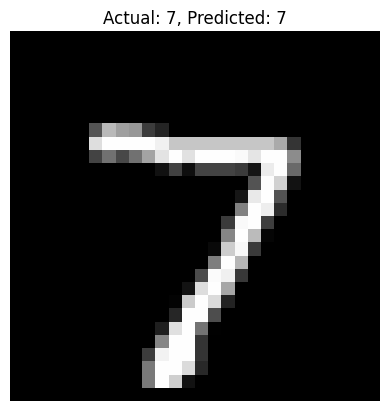

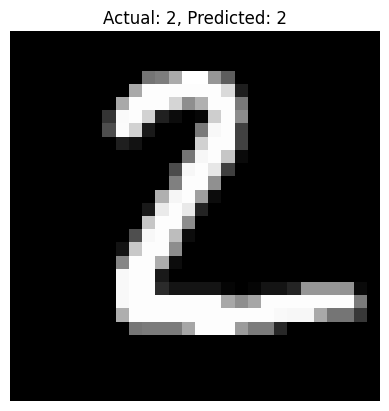

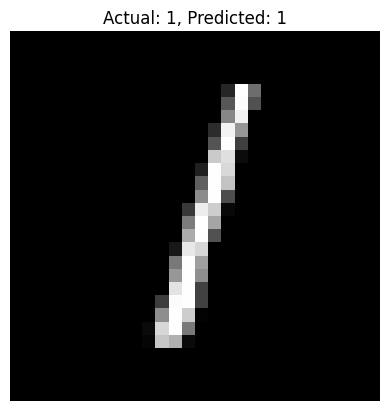

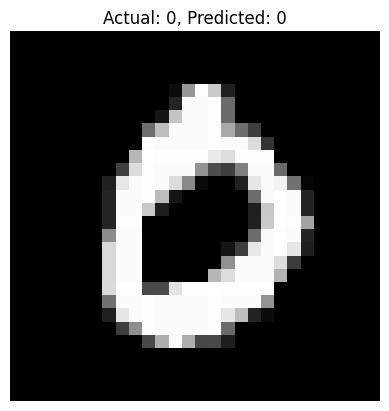

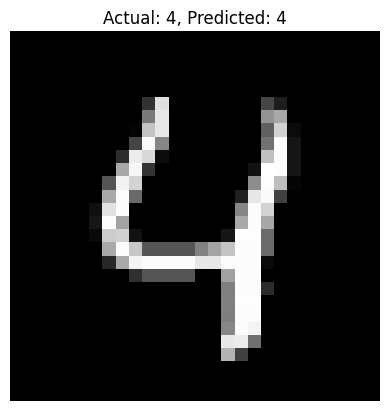

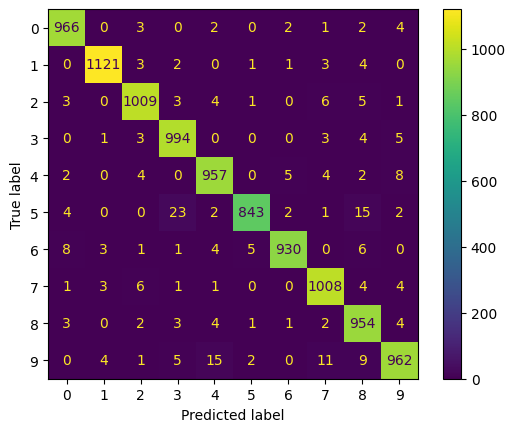

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict handwritten digits
y_pred = np.argmax(model.predict(X_test), axis=1)

# Display actual and predicted digits
for i in range(5):
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"Actual: {y_test[i]}, Predicted: {y_pred[i]}")
    plt.axis('off')
    plt.show()

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

---
### <b>Exercise 3: Fashion Product Image Classification
</b>

---

### Question 1: Build a deep ANN with multiple hidden layers.

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


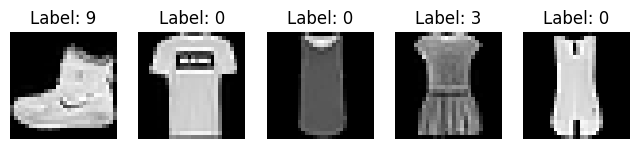

In [14]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Display dataset shape
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Display sample images
plt.figure(figsize=(8, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

In [15]:
# Build deep ANN with multiple hidden layers
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

# Train the model
history_deep = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8190 - loss: 0.5096 - val_accuracy: 0.8592 - val_loss: 0.3935
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8651 - loss: 0.3700 - val_accuracy: 0.8682 - val_loss: 0.3542
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8786 - loss: 0.3302 - val_accuracy: 0.8738 - val_loss: 0.3519
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8876 - loss: 0.3047 - val_accuracy: 0.8690 - val_loss: 0.3604
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8944 - loss: 0.2843 - val_accuracy: 0.8740 - val_loss: 0.3458
Test Accuracy: 87.05 %


### Question 2: Compare shallow and deep architectures

In [16]:
# Create a shallow ANN model
shallow_model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# Compile the shallow model
shallow_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the shallow model
history_shallow = shallow_model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# Evaluate both models
shallow_loss, shallow_accuracy = shallow_model.evaluate(
    X_test, y_test, verbose=0
)

deep_loss, deep_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

# Compare test accuracy
print("Shallow ANN Test Accuracy:",
      round(shallow_accuracy * 100, 2), "%")

print("Deep ANN Test Accuracy:",
      round(deep_accuracy * 100, 2), "%")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8151 - loss: 0.5340 - val_accuracy: 0.8547 - val_loss: 0.4064
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8612 - loss: 0.3968 - val_accuracy: 0.8638 - val_loss: 0.3672
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8741 - loss: 0.3529 - val_accuracy: 0.8675 - val_loss: 0.3540
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8824 - loss: 0.3252 - val_accuracy: 0.8698 - val_loss: 0.3533
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8896 - loss: 0.3048 - val_accuracy: 0.8715 - val_loss: 0.3493
Shallow ANN Test Accuracy: 86.84 %
Deep ANN Test Accuracy: 87.05 %


### Question 3: Compare Xavier and He initialization

In [17]:
# Create a model with the selected initializer
def create_model(initializer):
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),

        # Hidden layers
        keras.layers.Dense(
            128,
            activation='relu',
            kernel_initializer=initializer
        ),
        keras.layers.Dense(
            64,
            activation='relu',
            kernel_initializer=initializer
        ),

        # Output layer
        keras.layers.Dense(10, activation='softmax')
    ])

    # Compile the model
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# Xavier initialization
xavier_model = create_model('glorot_uniform')
xavier_model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    verbose=1
)

# Evaluate Xavier model
xavier_loss, xavier_accuracy = xavier_model.evaluate(
    X_test, y_test, verbose=0
)


# He initialization
he_model = create_model('he_normal')
he_model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    verbose=1
)

# Evaluate He model
he_loss, he_accuracy = he_model.evaluate(
    X_test, y_test, verbose=0
)


# Compare test accuracy
print("Xavier Initialization Accuracy:",
      round(xavier_accuracy * 100, 2), "%")

print("He Initialization Accuracy:",
      round(he_accuracy * 100, 2), "%")

Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8179 - loss: 0.5195
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8633 - loss: 0.3797
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8752 - loss: 0.3401
Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8204 - loss: 0.5095
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8633 - loss: 0.3770
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8768 - loss: 0.3374
Xavier Initialization Accuracy: 86.39 %
He Initialization Accuracy: 86.88 %


### Question 4: Apply dropout and L2 regularization

In [18]:
# Create an ANN model with Dropout and L2 regularization
regularized_model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),

    # Hidden layer with L2 regularization
    keras.layers.Dense(
        256,
        activation='relu',
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    # Apply dropout
    keras.layers.Dropout(0.3),

    # Hidden layer with L2 regularization
    keras.layers.Dense(
        128,
        activation='relu',
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    # Apply dropout
    keras.layers.Dropout(0.3),

    # Output layer
    keras.layers.Dense(10, activation='softmax')
])

# Compile the model
regularized_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history_regularized = regularized_model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# Evaluate the model
test_loss, test_accuracy = regularized_model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7804 - loss: 0.9323 - val_accuracy: 0.8443 - val_loss: 0.6360
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8312 - loss: 0.6480 - val_accuracy: 0.8523 - val_loss: 0.5484
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8357 - loss: 0.5926 - val_accuracy: 0.8507 - val_loss: 0.5210
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8395 - loss: 0.5626 - val_accuracy: 0.8600 - val_loss: 0.5035
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8431 - loss: 0.5463 - val_accuracy: 0.8585 - val_loss: 0.4885
Test Accuracy: 85.07 %


### Question 5: Plot training and validation loss

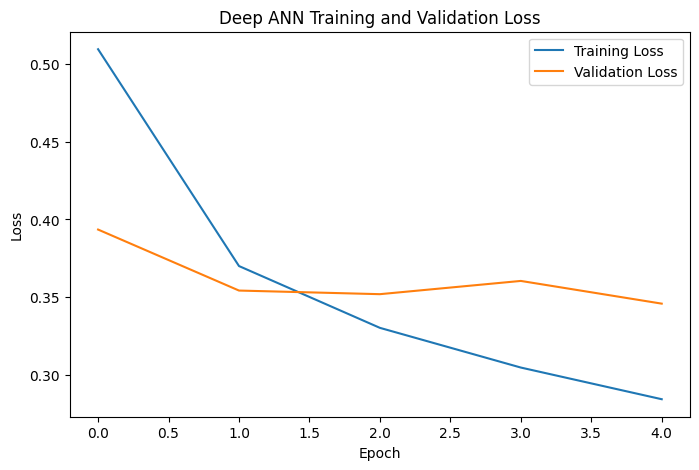

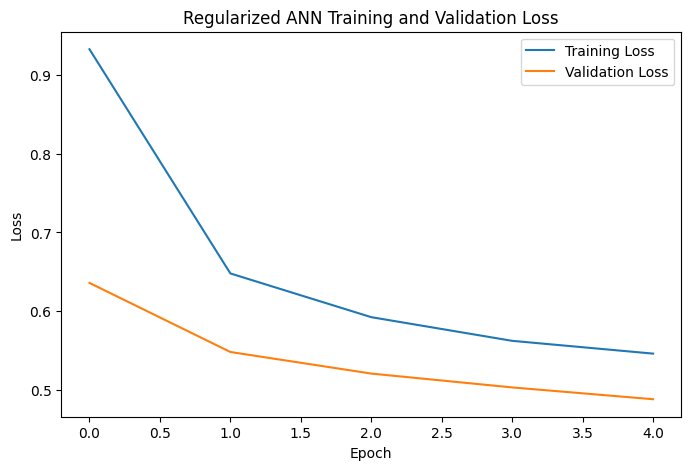

In [19]:
import matplotlib.pyplot as plt

# Plot loss for deep ANN
plt.figure(figsize=(8, 5))
plt.plot(history_deep.history['loss'], label='Training Loss')
plt.plot(history_deep.history['val_loss'], label='Validation Loss')

plt.title('Deep ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Plot loss for regularized ANN
plt.figure(figsize=(8, 5))
plt.plot(history_regularized.history['loss'], label='Training Loss')
plt.plot(history_regularized.history['val_loss'], label='Validation Loss')

plt.title('Regularized ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### Question 6: Analyze overfitting and optimize hyperparameters

Learning Rate: 0.001
Validation Accuracy: 86.53 %
Training Loss: 0.3746
Validation Loss: 0.3619

Learning Rate: 0.0005
Validation Accuracy: 86.0 %
Training Loss: 0.3952
Validation Loss: 0.3767

Learning Rate: 0.0001
Validation Accuracy: 83.67 %
Training Loss: 0.5196
Validation Loss: 0.4654

Best Learning Rate: 0.001
Best Validation Accuracy: 86.53 %


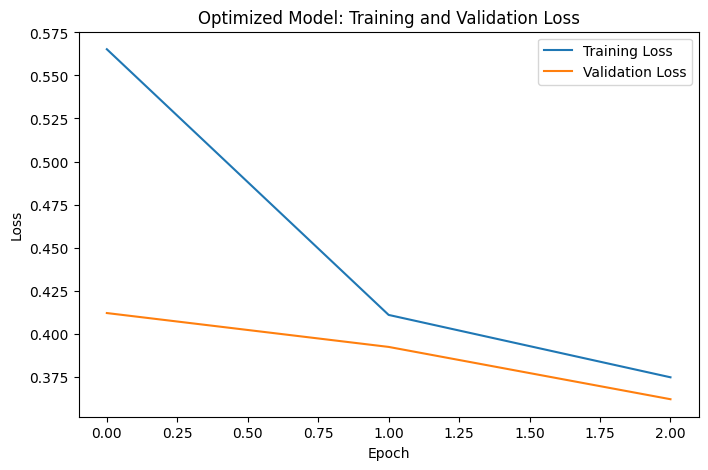

In [20]:
# Define learning rates to compare
learning_rates = [0.001, 0.0005, 0.0001]

results = []

for lr in learning_rates:

    optimized_model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(10, activation='softmax')
    ])

    # Compile the model
    optimized_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train the model
    history = optimized_model.fit(
        X_train, y_train,
        epochs=3,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    # Store validation accuracy
    val_accuracy = history.history['val_accuracy'][-1]
    results.append((lr, val_accuracy, history))

    print("Learning Rate:", lr)
    print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
    print("Training Loss:", round(history.history['loss'][-1], 4))
    print("Validation Loss:", round(history.history['val_loss'][-1], 4))
    print()

# Select the best learning rate
best_lr, best_accuracy, best_history = max(
    results, key=lambda x: x[1]
)

print("Best Learning Rate:", best_lr)
print("Best Validation Accuracy:", round(best_accuracy * 100, 2), "%")

# Plot loss for the best model
plt.figure(figsize=(8, 5))
plt.plot(best_history.history['loss'], label='Training Loss')
plt.plot(best_history.history['val_loss'], label='Validation Loss')
plt.title('Optimized Model: Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()